In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})

BASE = Path('ROUND_5')
DAYS = [2, 3, 4]

PRODUCTS = [
    'GALAXY_SOUNDS_BLACK_HOLES',
    'GALAXY_SOUNDS_PLANETARY_RINGS',
    'GALAXY_SOUNDS_SOLAR_WINDS',
    'GALAXY_SOUNDS_SOLAR_FLAMES',
    'GALAXY_SOUNDS_DARK_MATTER',
]
COLORS = ['#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4']

frames = []
for d in DAYS:
    df = pd.read_csv(BASE / f'prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    frames.append(df)
prices = pd.concat(frames, ignore_index=True)
prices['global_ts'] = (prices['day'] - DAYS[0]) * 1_000_000 + prices['timestamp']

mid = prices.pivot_table(index='global_ts', columns='product', values='mid_price')
day_starts = [(d - DAYS[0]) * 1_000_000 for d in DAYS]

fmt = mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k')

def vlines(ax):
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

print('Loaded', len(mid), 'timestamps across days', DAYS)

Loaded 30000 timestamps across days [2, 3, 4]


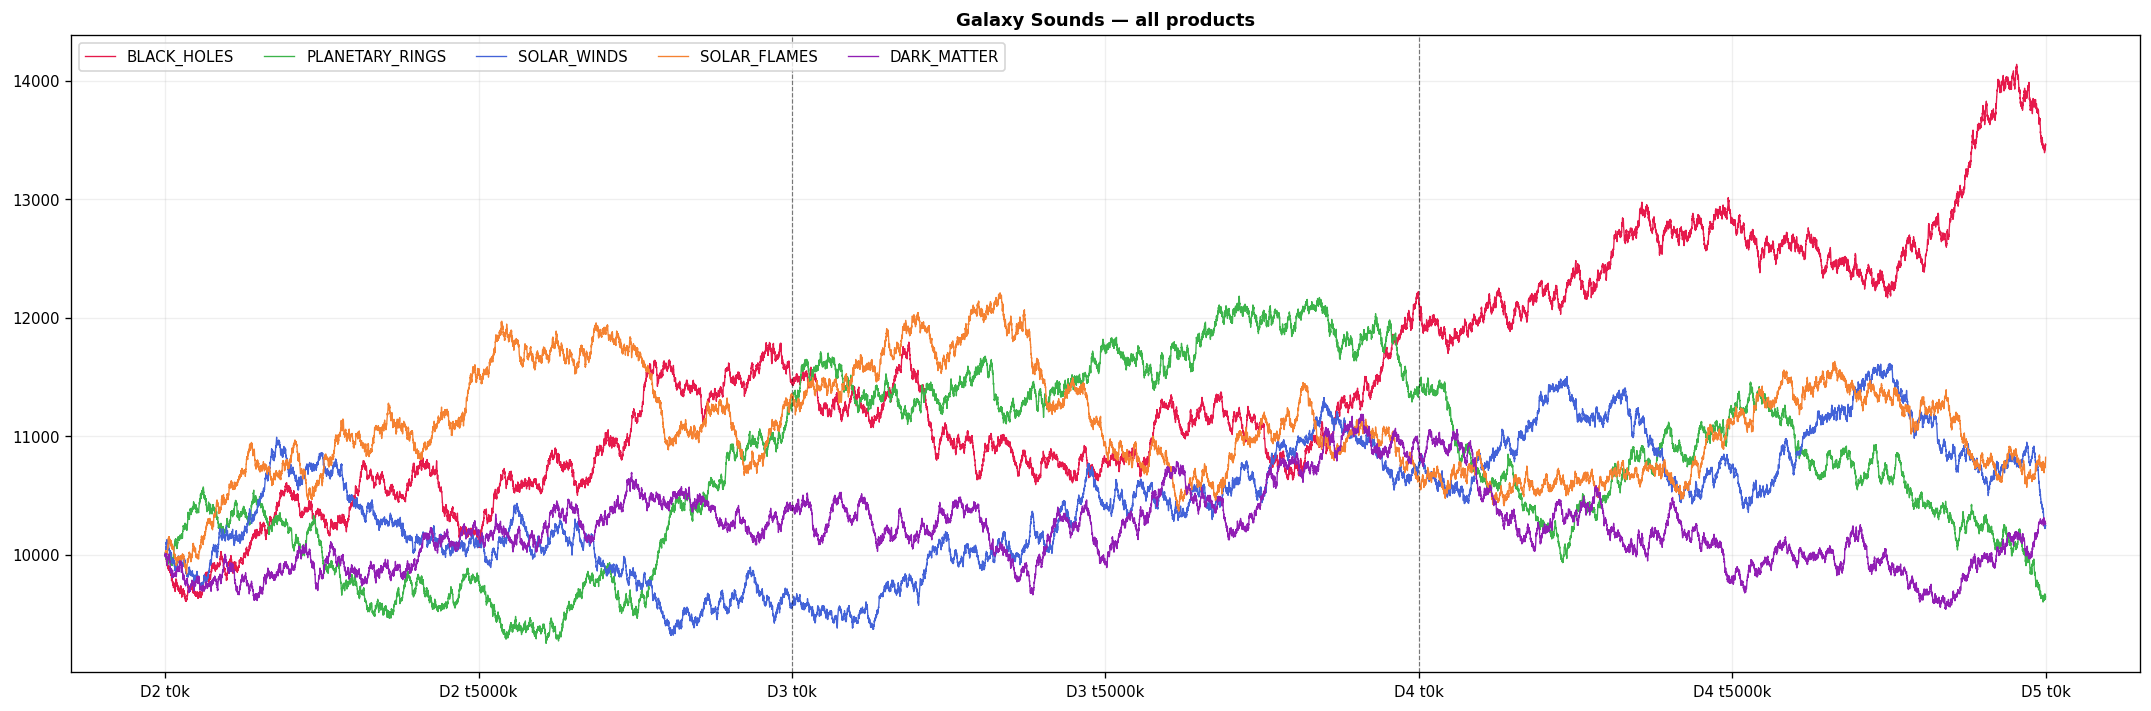

In [2]:
# All 5 products on one chart
fig, ax = plt.subplots(figsize=(18, 6))
for prod, col in zip(PRODUCTS, COLORS):
    s = mid[prod].dropna()
    ax.plot(s.index, s.values, color=col, linewidth=0.8, label=prod.replace('GALAXY_SOUNDS_', ''))
vlines(ax)
ax.xaxis.set_major_formatter(fmt)
ax.set_title('Galaxy Sounds — all products', fontweight='bold')
ax.legend(ncol=5, fontsize=9)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

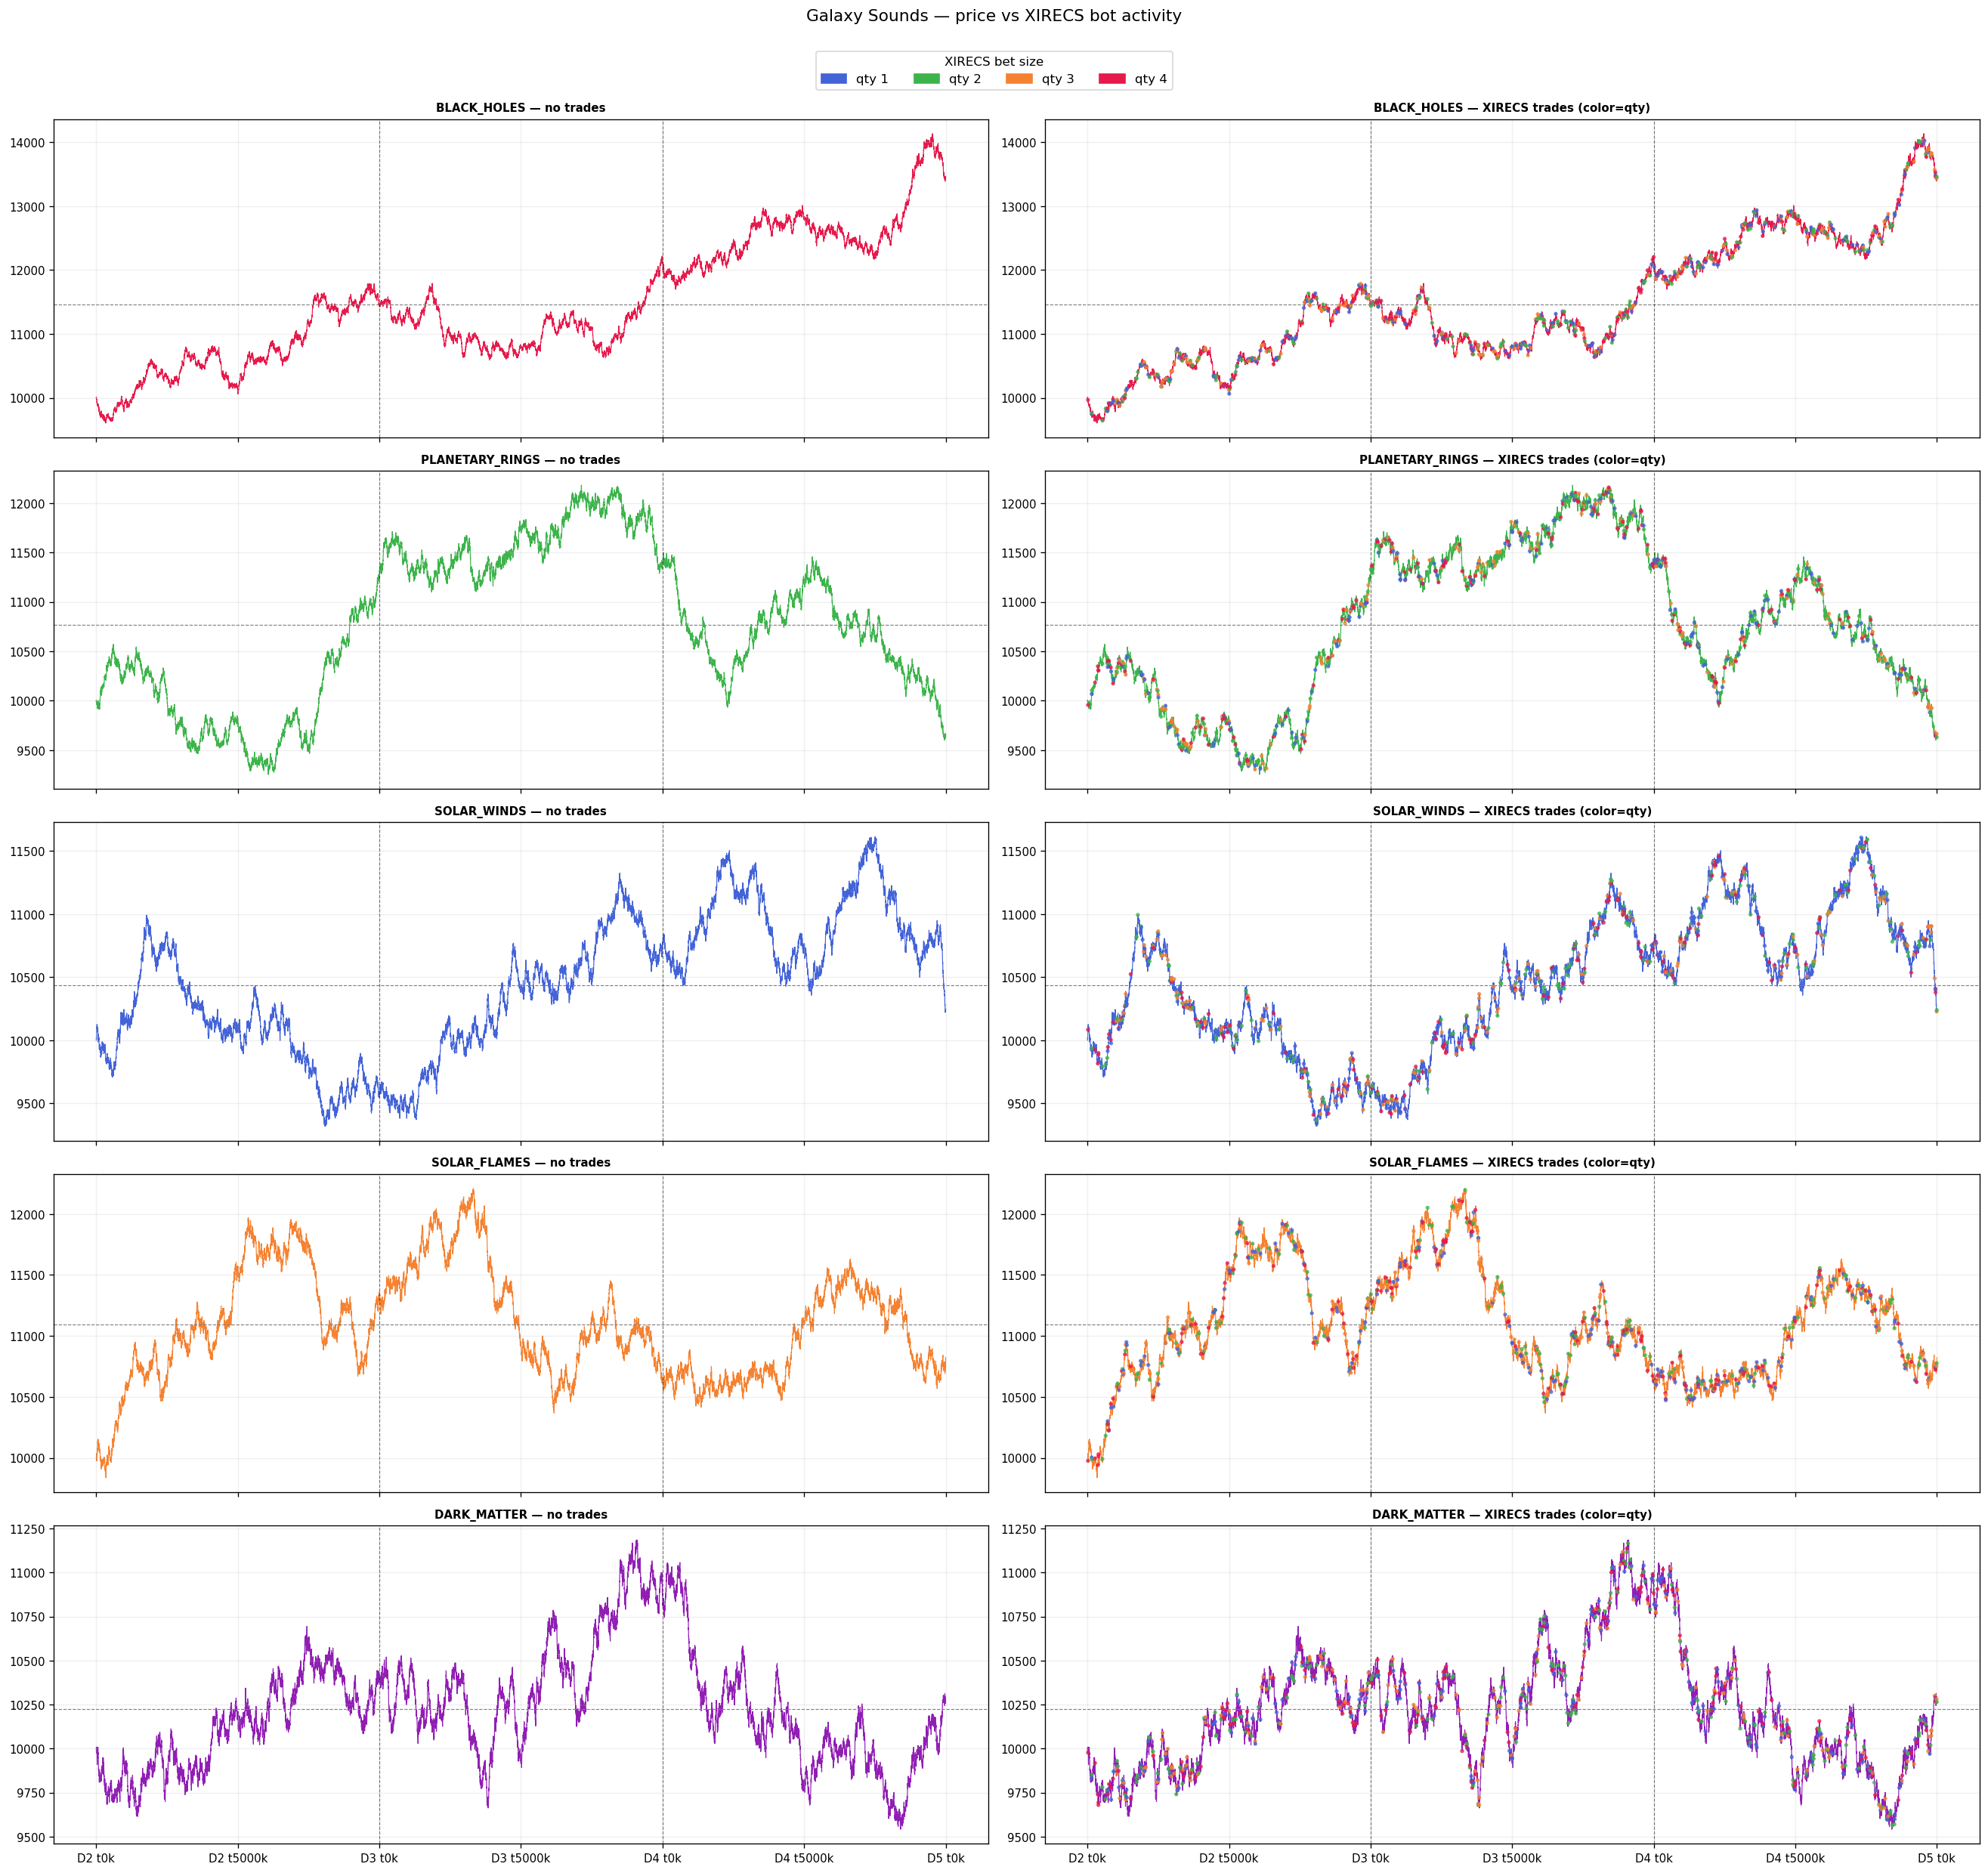

XIRECS bet size vs price position (z-score of price at trade time):
Product                     qty1 z   qty2 z   qty3 z   qty4 z
------------------------------------------------------------
BLACK_HOLES                 +0.050    +0.034    +0.003    -0.015
PLANETARY_RINGS             +0.033    +0.070    -0.079    +0.162
SOLAR_WINDS                 +0.079    +0.122    +0.002    -0.040
SOLAR_FLAMES                -0.082    +0.008    +0.003    -0.063
DARK_MATTER                 +0.022    +0.004    -0.077    +0.182


In [26]:
# Side-by-side: price only (left) vs price + XIRECS trades (right)
# All trades are XIRECS. Quantity ranges 1-4 — color reveals bet-size patterns.
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import numpy as np

trade_frames = []
for d in DAYS:
    tf = pd.read_csv(BASE / f'trades_round_5_day_{d}.csv', sep=';')
    tf['day'] = d
    trade_frames.append(tf)
trades = pd.concat(trade_frames, ignore_index=True)
trades['global_ts'] = (trades['day'] - DAYS[0]) * 1_000_000 + trades['timestamp']
trades = trades[trades['symbol'].isin(PRODUCTS)]

# Discrete colormap for quantities 1-4
Q_COLORS = {1: '#4363d8', 2: '#3cb44b', 3: '#f58231', 4: '#e6194b'}
legend_patches = [mpatches.Patch(color=c, label=f'qty {q}') for q, c in Q_COLORS.items()]

fig, axes = plt.subplots(len(PRODUCTS), 2, figsize=(22, 20), sharex=True)

for row, (prod, col) in enumerate(zip(PRODUCTS, COLORS)):
    name = prod.replace('GALAXY_SOUNDS_', '')
    s    = mid[prod].dropna()
    t    = trades[trades['symbol'] == prod].copy()
    t_colors = t['quantity'].map(Q_COLORS)

    for c in range(2):
        ax = axes[row, c]
        ax.plot(s.index, s.values, color=col, linewidth=0.7, zorder=1)
        ax.axhline(s.mean(), color='grey', linestyle='--', linewidth=0.7)
        vlines(ax)
        ax.grid(True, alpha=0.2)
        ax.xaxis.set_major_formatter(fmt)

    # Right: add trade dots
    axes[row, 1].scatter(t['global_ts'], t['price'], s=10, c=t_colors,
                         alpha=0.8, zorder=2, linewidths=0)

    axes[row, 0].set_title(f'{name} — no trades', fontweight='bold', fontsize=9)
    axes[row, 1].set_title(f'{name} — XIRECS trades (color=qty)', fontweight='bold', fontsize=9)

fig.legend(handles=legend_patches, loc='upper center', ncol=4,
           fontsize=10, title='XIRECS bet size', title_fontsize=10,
           bbox_to_anchor=(0.5, 1.01))
plt.suptitle('Galaxy Sounds — price vs XIRECS bot activity', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

# ── Timing analysis: do large bets cluster at price extremes? ─────────────────
print("XIRECS bet size vs price position (z-score of price at trade time):")
print(f"{'Product':<25} {'qty1 z':>8} {'qty2 z':>8} {'qty3 z':>8} {'qty4 z':>8}")
print('-' * 60)
for prod in PRODUCTS:
    s = mid[prod].dropna()
    t = trades[trades['symbol'] == prod].copy()
    t['price_z'] = (t['price'] - s.mean()) / s.std()
    row_vals = [f"{t[t['quantity']==q]['price_z'].mean():>+8.3f}" for q in [1,2,3,4]]
    print(f"{prod.replace('GALAXY_SOUNDS_',''):<25} {'  '.join(row_vals)}")

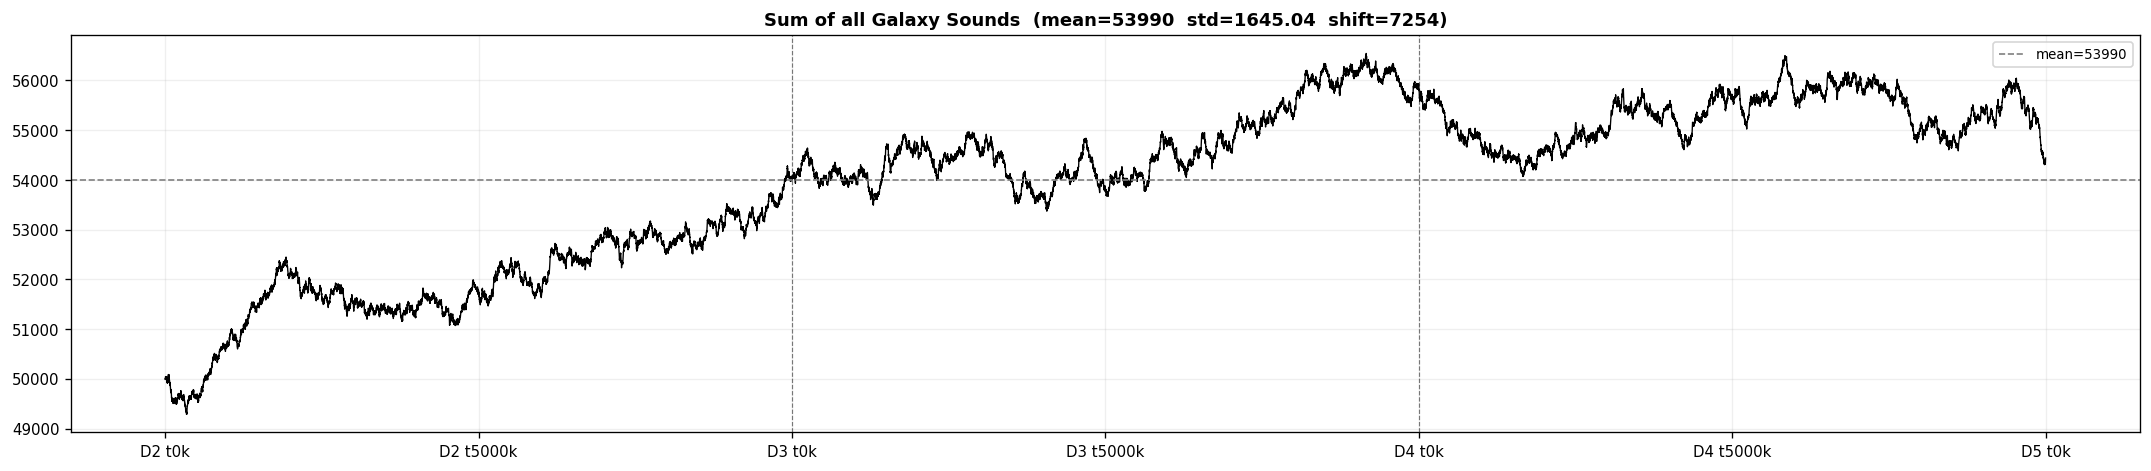

Sum CV (std/mean): 3.0469%


In [ ]:
import numpy as np

_gs = mid[PRODUCTS].dropna()
_idx = _gs.index
SHORT = [p.replace('GALAXY_SOUNDS_', '') for p in PRODUCTS]

# ── Sum of all sounds ─────────────────────────────────────────────────────────
gs_sum = _gs.sum(axis=1)

fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(_idx, gs_sum.values, color='#000000', linewidth=0.8)
ax.axhline(gs_sum.mean(), color='grey', linestyle='--', linewidth=1, label=f'mean={gs_sum.mean():.0f}')
vlines(ax)
ax.set_title(f'Sum of all Galaxy Sounds  (mean={gs_sum.mean():.0f}  std={gs_sum.std():.2f}  shift={gs_sum.max()-gs_sum.min():.0f})', fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.2); ax.xaxis.set_major_formatter(fmt)
plt.tight_layout(); plt.show()
print(f'Sum CV (std/mean): {gs_sum.std()/gs_sum.mean():.4%}')

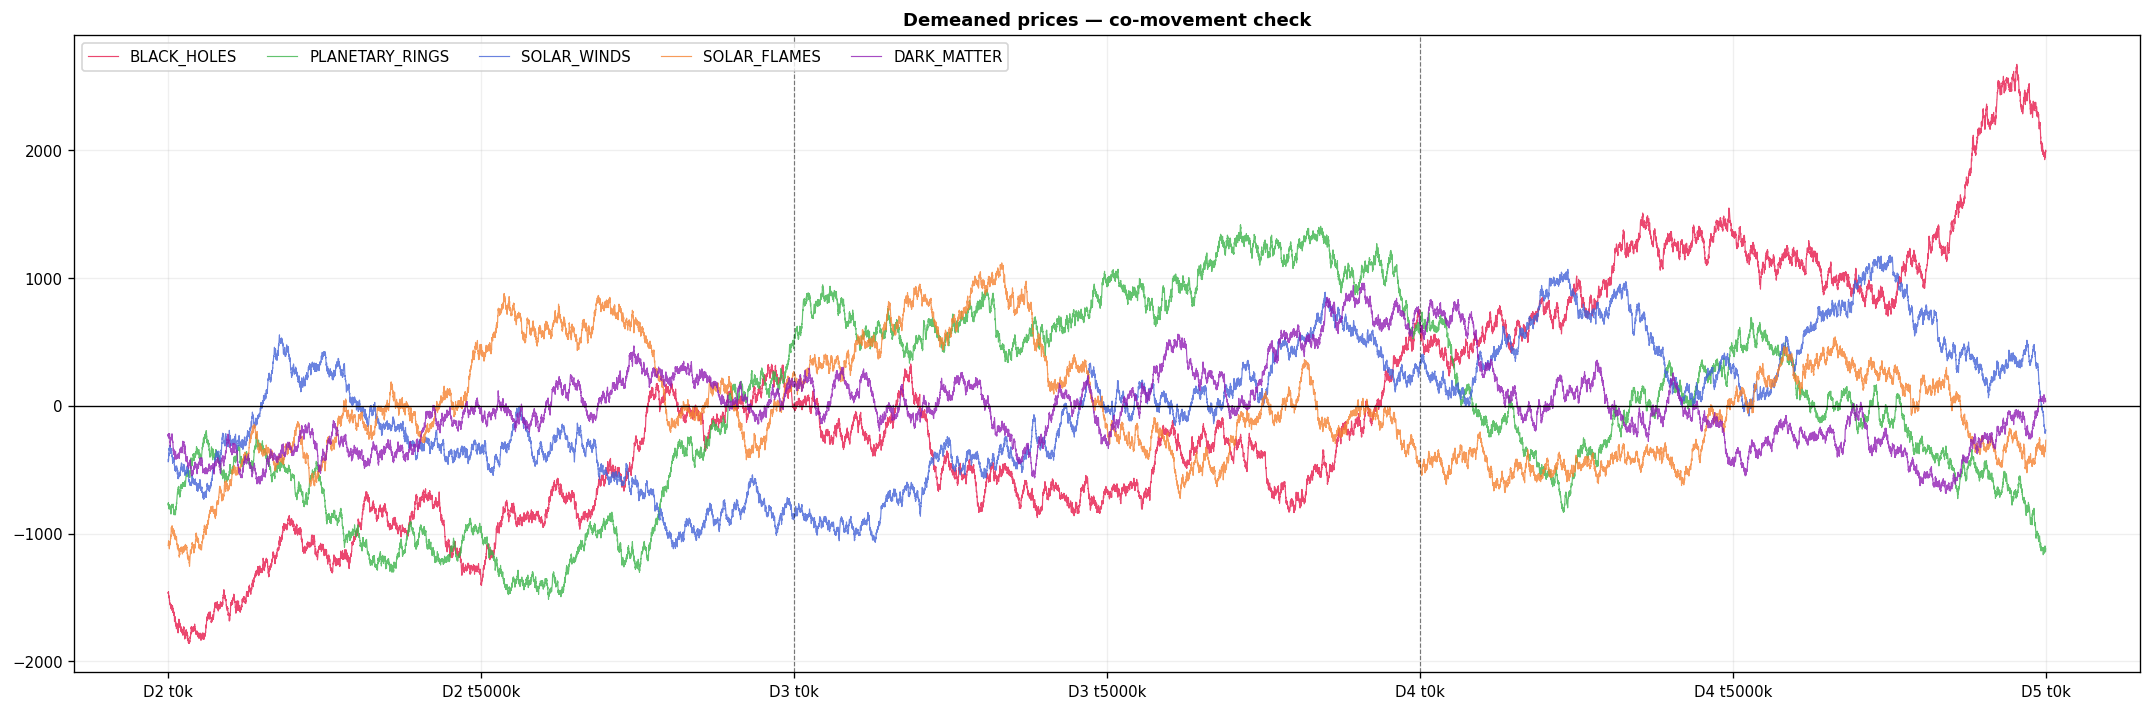

In [19]:
# ── Demeaned overlay — do they move together? ────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 6))
for prod, col, name in zip(PRODUCTS, COLORS, SHORT):
    s = _gs[prod]
    ax.plot(_idx, (s - s.mean()).values, color=col, linewidth=0.7, alpha=0.8, label=name)
ax.axhline(0, color='black', linewidth=0.8)
vlines(ax)
ax.set_title('Demeaned prices — co-movement check', fontweight='bold')
ax.legend(ncol=5, fontsize=9); ax.grid(True, alpha=0.2); ax.xaxis.set_major_formatter(fmt)
plt.tight_layout(); plt.show()

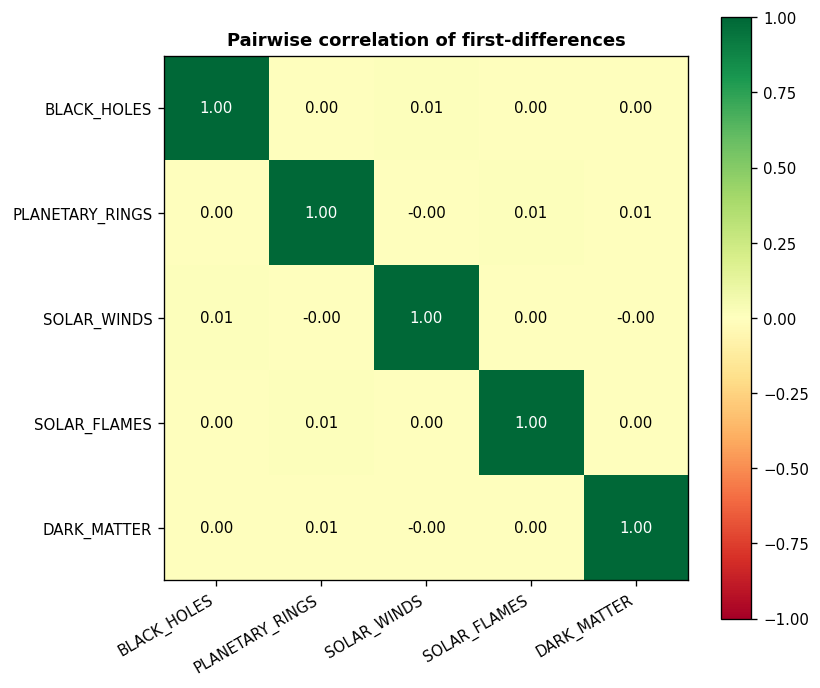

In [20]:
# ── Pairwise correlation heatmap ──────────────────────────────────────────────
import matplotlib.colors as mcolors

corr = _gs.diff().dropna().corr()
corr.columns = corr.index = SHORT

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='RdYlGn')
ax.set_xticks(range(len(SHORT))); ax.set_xticklabels(SHORT, rotation=30, ha='right')
ax.set_yticks(range(len(SHORT))); ax.set_yticklabels(SHORT)
for i in range(len(SHORT)):
    for j in range(len(SHORT)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=9,
                color='black' if abs(corr.values[i,j]) < 0.6 else 'white')
plt.colorbar(im, ax=ax)
ax.set_title('Pairwise correlation of first-differences', fontweight='bold')
plt.tight_layout(); plt.show()

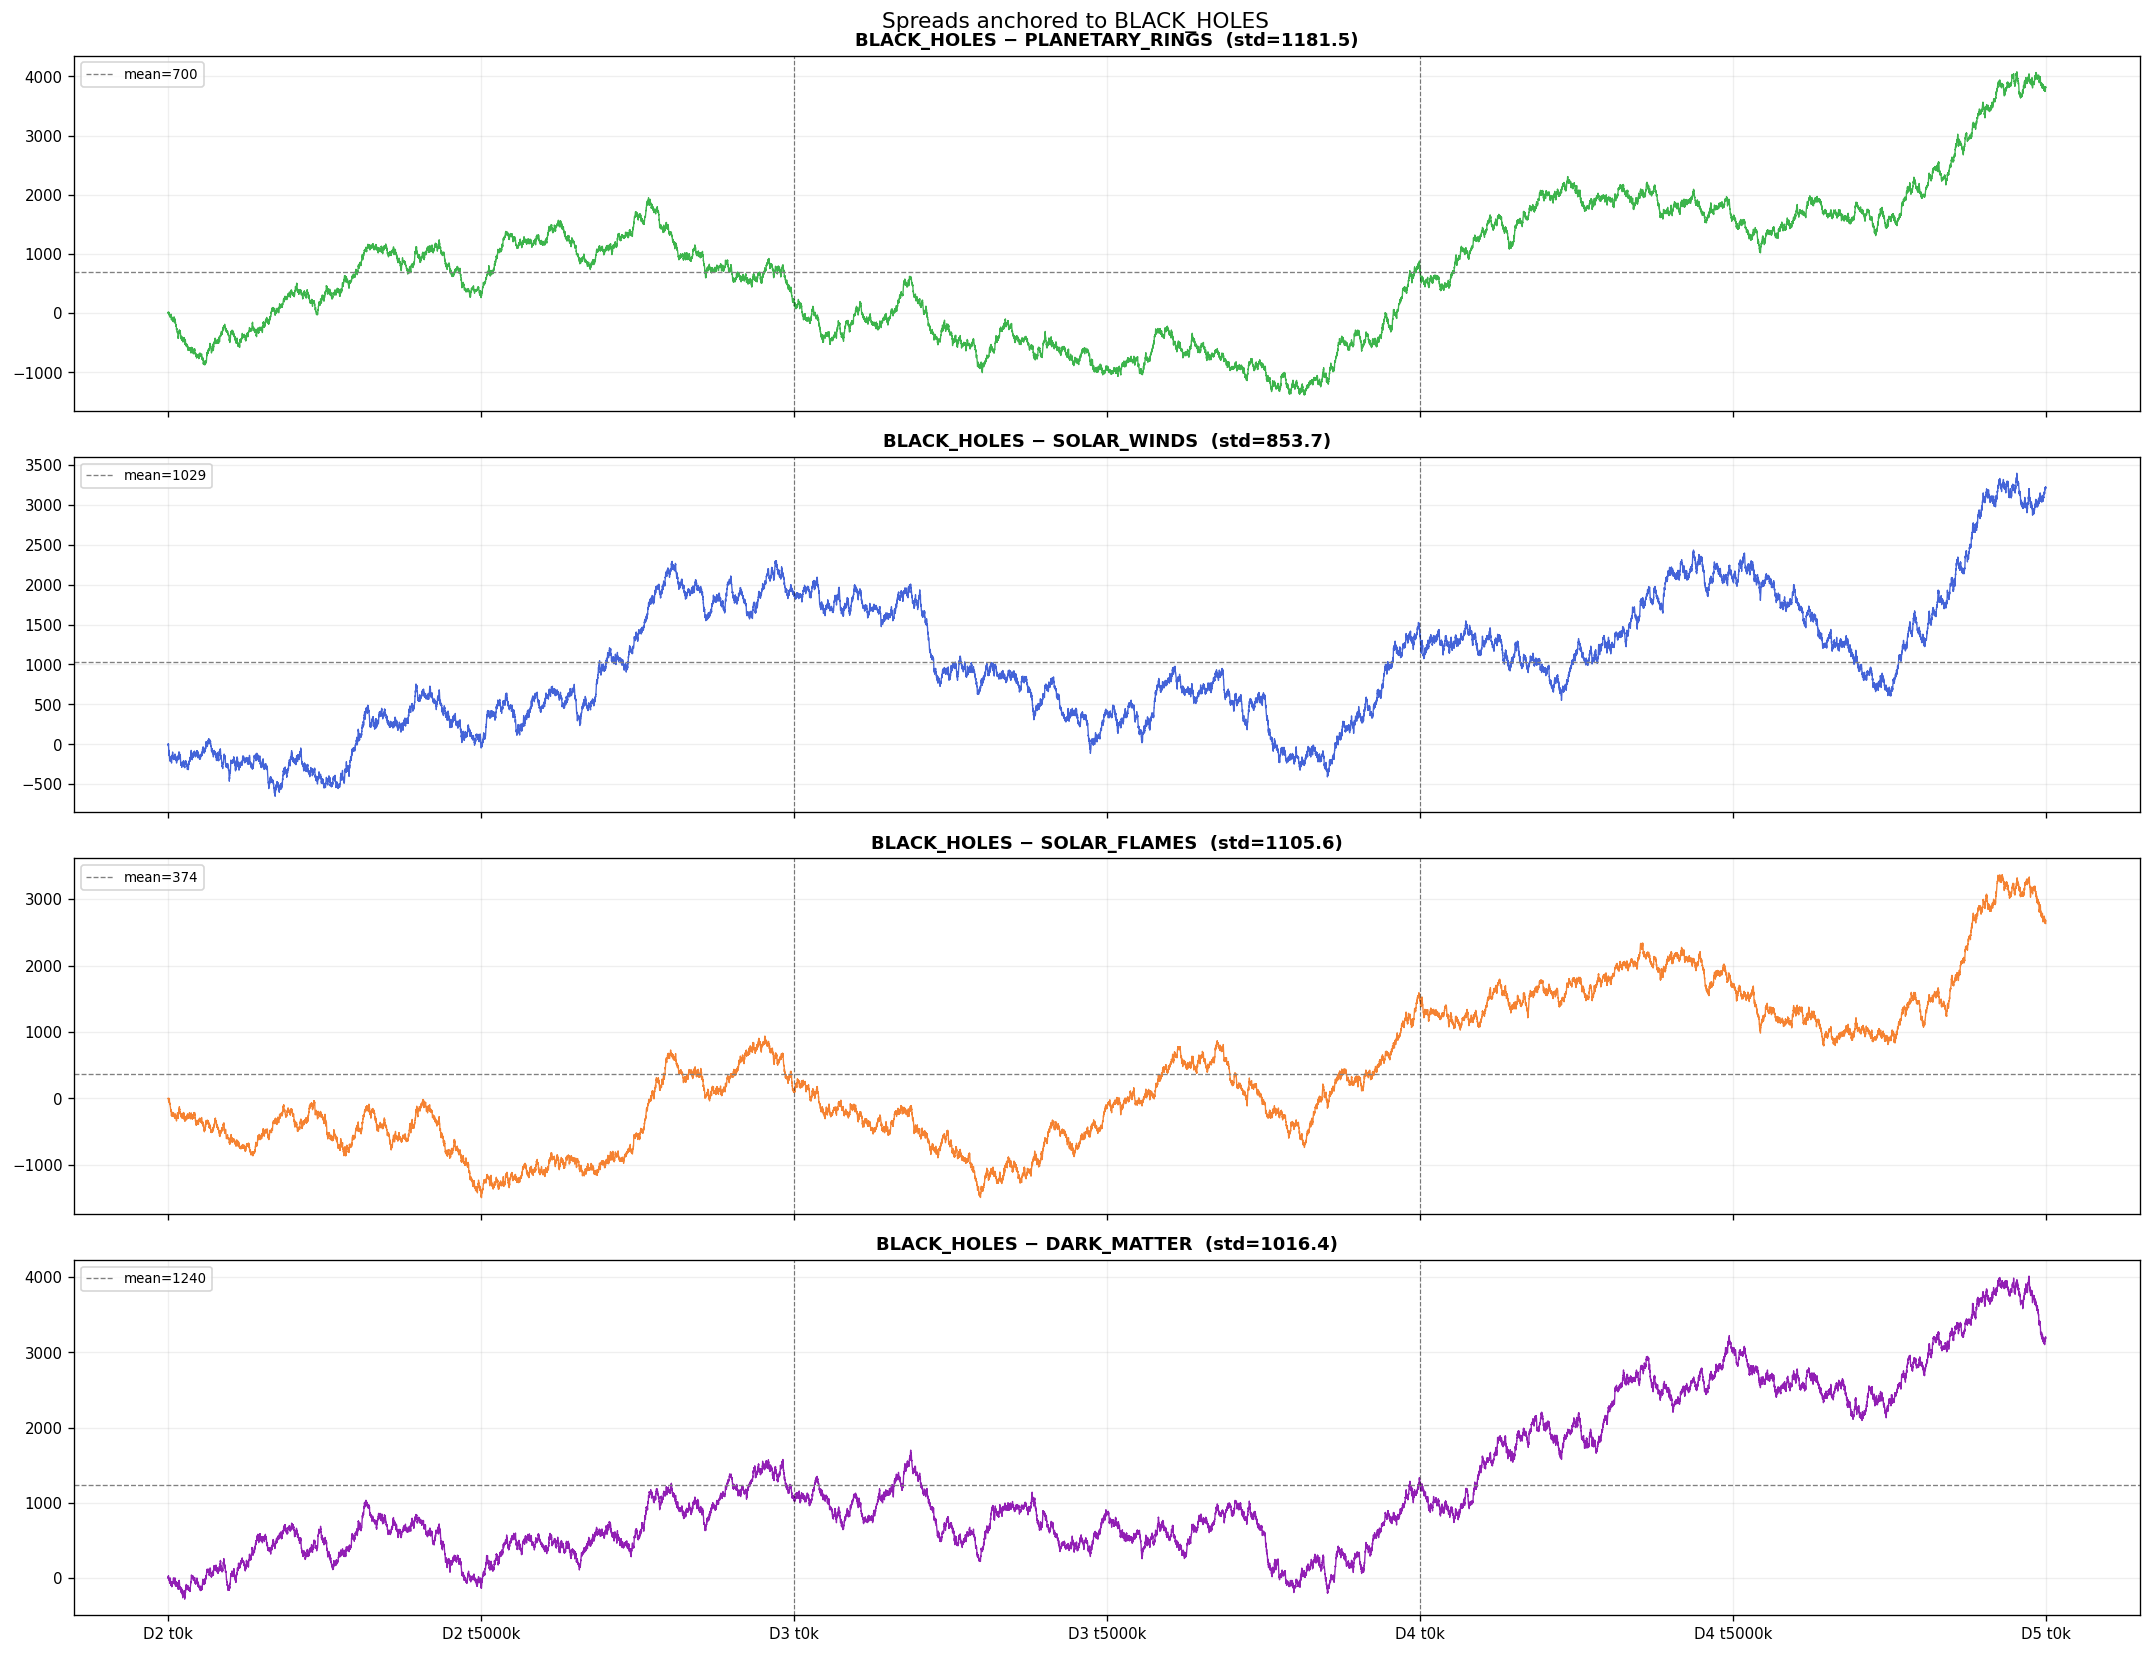

In [21]:
# ── Spreads: BLACK_HOLES - each other product ────────────────────────────────
anchor = 'GALAXY_SOUNDS_BLACK_HOLES'
others = [p for p in PRODUCTS if p != anchor]
other_cols = [p.replace('GALAXY_SOUNDS_', '') for p in others]
other_colors = [c for p, c in zip(PRODUCTS, COLORS) if p != anchor]

fig, axes = plt.subplots(len(others), 1, figsize=(18, 14), sharex=True)
for ax, prod, col, name in zip(axes, others, other_colors, other_cols):
    spread = _gs[anchor] - _gs[prod]
    ax.plot(_idx, spread.values, color=col, linewidth=0.8)
    ax.axhline(spread.mean(), color='grey', linestyle='--', linewidth=0.8, label=f'mean={spread.mean():.0f}')
    vlines(ax)
    ax.set_title(f'BLACK_HOLES − {name}  (std={spread.std():.1f})', fontweight='bold')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.2); ax.xaxis.set_major_formatter(fmt)
plt.suptitle('Spreads anchored to BLACK_HOLES', fontsize=13)
plt.tight_layout(); plt.show()

In [22]:
# ── AC1 for each product (MR signal check) ───────────────────────────────────
from statsmodels.tsa.stattools import acf, adfuller

def hurst(series, max_lag=100):
    lags = range(2, max_lag)
    tau  = [np.std(np.subtract(series[lag:], series[:-lag])) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0]

print(f"{'Product':<22} {'AC1':>8} {'Hurst H':>10} {'Trend?':>14} {'ADF p':>10}")
print('-' * 68)
for prod, name in zip(PRODUCTS, SHORT):
    s = _gs[prod].dropna()
    a1 = acf(s.diff().dropna(), nlags=1, fft=True)[1]
    H  = hurst(s.values)
    p  = adfuller(s.values, autolag='AIC')[1]
    t  = 'TRENDING' if H > 0.55 else ('MR' if H < 0.45 else 'random walk')
    print(f'{name:<22} {a1:>+8.4f} {H:>10.3f} {t:>14} {p:>10.4f}')

Product                     AC1    Hurst H         Trend?      ADF p
--------------------------------------------------------------------
BLACK_HOLES             -0.0167      0.507    random walk     0.8858
PLANETARY_RINGS         -0.0040      0.508    random walk     0.7409
SOLAR_WINDS             -0.0078      0.501    random walk     0.3978
SOLAR_FLAMES            -0.0121      0.496    random walk     0.0639
DARK_MATTER             -0.0120      0.508    random walk     0.0705
